# 02 · Três métodos de seleção de features e votação

Métodos (todos ajustados **apenas no treino acumulado**; a validação e o teste não participam):
1. **SelectKBest** com `f_regression` (estatística F de regressão univariada);
2. **Importância por Random Forest** (redução média de impureza);
3. **RFE** com `Ridge` sobre atributos padronizados.

**Regra de votação (definida antes da comparação, em `config.yaml`)**: cada método vota em suas **top-5** features. É eleita a feature com **≥ 2 dos 3 votos**. Se forem eleitas menos de **4**, completa-se pelo **menor ranking médio** entre os métodos. A ordem final usa votos (desc) e depois ranking médio (asc).

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.utils import preparar_ambiente, carregar_config, carregar_contexto, salvar_contexto, dir_evidencias, configurar_mlflow
preparar_ambiente()
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.ingestao import carregar_treino_acumulado
from src.preprocessamento import lista_features
from src.features import votar

ctx = carregar_contexto()
ev = dir_evidencias(ctx["cycle_id"])
treino = carregar_treino_acumulado(cfg)
assert len(treino) == ctx["n_treino"], "Treino diferente do registrado no ETL"
features = lista_features(cfg)

tabela, eleitas, metodos, criterio = votar(treino, features, cfg)
print("cycle_id:", ctx["cycle_id"], "| data_version:", ctx["data_version"])
for m, v in metodos.items():
    print(f"  {m:28s} -> {v}")
print("\nFeatures eleitas:", eleitas, "| critério:", criterio)
display(tabela[["feature", "voto_kbest", "voto_rf", "voto_rfe", "votos", "rank_kbest", "rank_rf", "rank_rfe", "ranking_medio", "eleita"]])

cycle_id: c20261124T225840Z-local | data_version: v1-f78d2fdb
  selectkbest_f_regression     -> ['aglomerante_total', 'cimento', 'idade', 'log_idade', 'relacao_agua_aglomerante']
  importancia_random_forest    -> ['aglomerante_total', 'idade', 'log_idade', 'relacao_agua_aglomerante', 'relacao_agua_cimento']
  rfe_ridge                    -> ['aglomerante_total', 'agua', 'cimento', 'idade', 'log_idade']

Features eleitas: ['idade', 'aglomerante_total', 'log_idade', 'relacao_agua_aglomerante', 'cimento'] | critério: >= 2 votos


,feature,voto_kbest,voto_rf,voto_rfe,votos,rank_kbest,rank_rf,rank_rfe,ranking_medio,eleita
0,idade,1,1,1,3,3,2,3,2.666667,1
1,aglomerante_total,1,1,1,3,2,5,4,3.666667,1
2,log_idade,1,1,1,3,4,3,5,4.000000,1
3,relacao_agua_aglomerante,1,1,0,2,1,1,8,3.333333,1
4,cimento,1,0,1,2,5,6,1,4.000000,1
5,relacao_agua_cimento,0,1,0,1,6,4,7,5.666667,0
6,agua,0,0,1,1,8,12,2,7.333333,0
7,escoria,0,0,0,0,11,9,6,8.666667,0
8,agregado_graudo,0,0,0,0,10,7,10,9.000000,0
9,superplastificante,0,0,0,0,7,10,12,9.666667,0


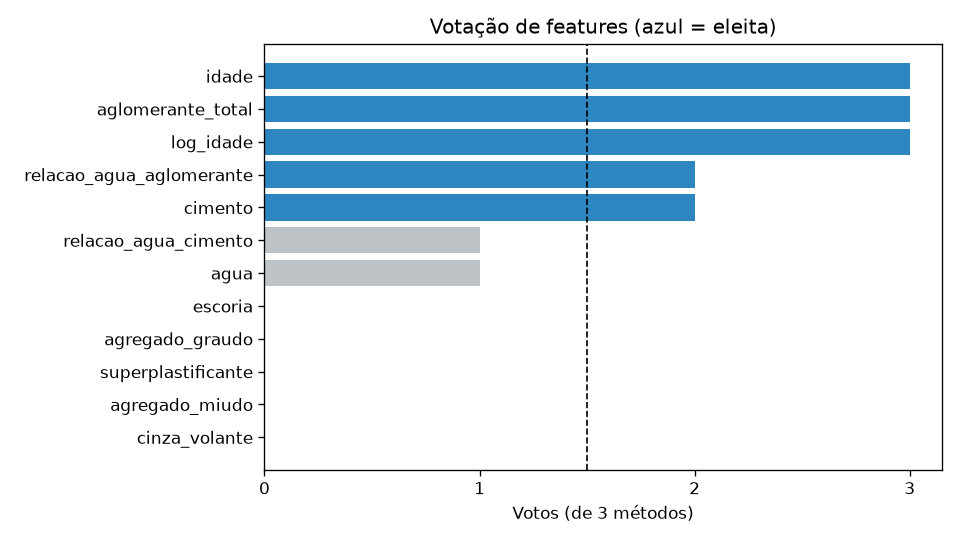

{'cycle_id': 'c20261124T225840Z-local',
 'data_version': 'v1-f78d2fdb',
 'lote': 'lote_01.csv',
 'n_treino': 342,
 'gatilho': 'local',
 'etl': {'linhas_recebidas': 342,
  'removidas_alvo_ausente': 0,
  'removidas_traco_incompleto': 0,
  'removidas_fora_da_faixa': 0,
  'removidas_duplicadas_no_lote': 0,
  'removidas_ja_incorporadas': 0,
  'ausentes_para_imputacao': 0,
  'linhas_aceitas': 342},
 'drift_resumo': None,
 'drift_alerta': False,
 'run_etl': 'f09e398d1a8940c68847bd9666c74572',
 'features_eleitas': ['idade',
  'aglomerante_total',
  'log_idade',
  'relacao_agua_aglomerante',
  'cimento'],
 'criterio_votacao': '>= 2 votos',
 'selecao_por_metodo': {'selectkbest_f_regression': ['aglomerante_total',
   'cimento',
   'idade',
   'log_idade',
   'relacao_agua_aglomerante'],
  'importancia_random_forest': ['aglomerante_total',
   'idade',
   'log_idade',
   'relacao_agua_aglomerante',
   'relacao_agua_cimento'],
  'rfe_ridge': ['aglomerante_total', 'agua', 'cimento', 'idade', 'log_ida

In [3]:
tabela.to_csv(ev / "votacao_features.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
cores = ["#2e86c1" if e else "#bdc3c7" for e in tabela["eleita"]]
ax.barh(tabela["feature"], tabela["votos"], color=cores)
ax.invert_yaxis(); ax.set_xticks([0, 1, 2, 3]); ax.set_xlabel("Votos (de 3 métodos)")
ax.axvline(cfg["votacao"]["votos_minimos"] - 0.5, ls="--", c="k", lw=1)
ax.set_title("Votação de features (azul = eleita)")
fig.tight_layout(); fig.savefig(ev / "votacao_features.png", dpi=120); plt.close(fig)
display(Image(str(ev / "votacao_features.png")))

mlflow = configurar_mlflow(cfg)
with mlflow.start_run(run_name=f"votacao_{ctx['cycle_id']}") as run:
    mlflow.set_tags({"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"], "etapa": "votacao"})
    mlflow.log_params({
        "metodo_votacao": f"top{cfg['votacao']['top_k']}_por_metodo_min{cfg['votacao']['votos_minimos']}_votos",
        "metodos": ",".join(cfg["votacao"]["metodos"]),
        "top_k": cfg["votacao"]["top_k"], "min_features": cfg["votacao"]["min_features"],
        "features_eleitas": ",".join(eleitas), "criterio_aplicado": criterio,
    })
    mlflow.log_metric("n_features_eleitas", len(eleitas))
    for _, r in tabela.iterrows():
        mlflow.log_metric(f"votos_{r['feature']}", int(r["votos"]))
    mlflow.log_dict(metodos, "votacao/selecao_por_metodo.json")
    mlflow.log_artifact(str(ev / "votacao_features.csv"), "votacao")
    mlflow.log_artifact(str(ev / "votacao_features.png"), "votacao")

salvar_contexto({"features_eleitas": eleitas, "criterio_votacao": criterio, "selecao_por_metodo": metodos, "run_votacao": run.info.run_id})